# Strategy grid: four ways of writing Irish mutations × five vocabulary sizes

**Goal:** compare how four layouts of the same Irish text affect the tokenizer's token distribution:

| Layout | Example | Source |
|---|---|---|
| raw | `mo chat`, `ár gcat` | baseline `OpenSubtitles.en-ga.ga` |
| normalized | `mo [LEN] cat` | baseline `OpenSubtitles.en-ga.normalized.txt` |
| fused | `mo [LEN]cat` | baseline `OpenSubtitles.en-ga.normalized_fused.txt` |
| postfix (new) | `mo cat[LEN]` | built in this notebook |

For each layout and each vocabulary size (1k, 2k, 4k, 8k, 16k) we train a byte-level BPE tokenizer with **the baseline's exact settings**, re-tokenize the corpus, and measure total tokens, Shannon entropy, Rényi entropy (α = 2.5), Rényi efficiency, and Rényi with the stray space token removed.

**Before running:** put this notebook in the `gaeilge_renyi_test` folder (next to `irish_mutations.py`), and select the `.venv` kernel in VS Code.

## Step 1 — Setup
`BASE_DIR` is the `gaeilge_renyi_test` folder (the baseline experiment). `"."` works when this notebook sits inside it; otherwise put the full path. Adding it to `sys.path` lets us import the baseline `irish_mutations.py`.

In [1]:
import sys, math, re
from collections import Counter
from pathlib import Path

BASE_DIR = Path(".").resolve()          # <- change if the notebook is elsewhere
sys.path.insert(0, str(BASE_DIR))

from irish_mutations import demutate_word, remutate_word, _WORD_RE   # baseline mutation rules
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.trainers import BpeTrainer

print("Using baseline folder:", BASE_DIR)

Using baseline folder: D:\Research Ireland\Projects\Tokenisation\gaeilge_renyi_test\gaeilge_renyi_test


## Step 2 — Marker names and the raw corpus
The same three markers as the baseline. `[ECL^]` is the rare case for a sentence-initial capitalised eclipsed word.

In [2]:
MARKERS = ["[LEN]", "[ECL]", "[ECL^]"]
raw = (BASE_DIR / "OpenSubtitles.en-ga.ga").read_text(encoding="utf-8")
print(f"{len(raw.splitlines()):,} lines, {len(raw):,} characters")
print(raw.splitlines()[8])

20,035 lines, 655,401 characters
I bpoll sa talamh bhí hobbit ina chónaí.


## Step 3 — The postfix layout
`postfix()` is the baseline `normalize_text` with one change: it writes `root[MARKER]` instead of `[MARKER] root`. It uses the baseline `demutate_word` to decide *whether* a word is mutated, so it flags exactly the same words.
`depostfix()` reverses it with the baseline `remutate_word`.

In [3]:
def postfix(text):
    def repl(m):
        marker, root = demutate_word(m.group(0))      # baseline rule: "chat" -> ("LEN", "cat")
        return m.group(0) if marker is None else f"{root}[{marker}]"
    return _WORD_RE.sub(repl, text)

PF_RE = re.compile(r"([A-Za-zÁÉÍÓÚáéíóú]+(?:-[A-Za-zÁÉÍÓÚáéíóú]+)*)\[(LEN|ECL\^?)\]")

def depostfix(text):
    return PF_RE.sub(lambda m: remutate_word(m.group(2), m.group(1)), text)

s = "mo chat agus ár gcat"
print(postfix(s), "->", depostfix(postfix(s)))

mo cat[LEN] agus ár cat[ECL] -> mo chat agus ár gcat


## Step 4 — Build the four corpora and check postfix is lossless
If converting back doesn't reproduce the raw text byte for byte, this cell stops with an error.

In [4]:
pf = postfix(raw)
assert depostfix(pf) == raw, "postfix is not lossless"
print("Lossless round trip: OK")

corpora = {
    "raw":        raw,
    "normalized": (BASE_DIR / "OpenSubtitles.en-ga.normalized.txt").read_text(encoding="utf-8"),
    "fused":      (BASE_DIR / "OpenSubtitles.en-ga.normalized_fused.txt").read_text(encoding="utf-8"),
    "postfix":    pf,
}
for name, text in corpora.items():
    print(f"{name:<11} {text.splitlines()[11]}")

Lossless round trip: OK
raw         Bhí hobbit ina chónaí i bpoll sa talamh.
normalized  [LEN] Bí hobbit ina [LEN] cónaí i [ECL] poll sa talamh.
fused       [LEN]Bí hobbit ina [LEN]cónaí i [ECL]poll sa talamh.
postfix     Bí[LEN] hobbit ina cónaí[LEN] i poll[ECL] sa talamh.


## Step 5 — Entropy formula
Same as the baseline `renyi_entropy()`: Shannon when α = 1, Rényi otherwise, in bits.
Sanity check: four equally likely tokens give exactly 2 bits for any α.

In [5]:
def entropy(counts, alpha):
    total = sum(counts.values())
    ps = [c / total for c in counts.values()]
    if alpha == 1:
        return -sum(p * math.log2(p) for p in ps)
    return math.log2(sum(p ** alpha for p in ps)) / (1 - alpha)

print(entropy(Counter("abcd"), 1), entropy(Counter("abcd"), 2.5))

2.0 2.0


## Step 6 — One experiment: train, tokenize, count, measure
Training settings match the baseline `train_bpe` exactly (byte-level BPE, no added prefix space, min merge frequency 2, markers as special tokens).

Two counts are kept:
* `counts` — every token, as the baseline counts them.
* `counts_no_stray` — the same, but skipping a lone space token `Ġ` that sits directly before a marker. This simulates "what if the stray space didn't exist?". For raw and postfix it equals `counts`.

In [6]:
def run_one(name, text, vocab_size):
    tok = Tokenizer(BPE())
    tok.pre_tokenizer = ByteLevel(add_prefix_space=False)
    special = [] if name == "raw" else MARKERS
    trainer = BpeTrainer(vocab_size=vocab_size, min_frequency=2, special_tokens=special,
                         initial_alphabet=ByteLevel.alphabet(), show_progress=False)
    tok.train_from_iterator(text.splitlines(), trainer)

    counts, counts_no_stray = Counter(), Counter()
    for enc in tok.encode_batch(text.splitlines()):
        counts.update(enc.ids)
        for i, (tid, t) in enumerate(zip(enc.ids, enc.tokens)):
            if t == "Ġ" and i + 1 < len(enc.tokens) and enc.tokens[i + 1] in MARKERS:
                continue
            counts_no_stray[tid] += 1

    v_trained = tok.get_vocab_size()
    h25 = entropy(counts, 2.5)
    return {
        "layout": name, "vocab_target": vocab_size, "vocab_trained": v_trained,
        "tokens_used": len(counts), "total_tokens": sum(counts.values()),
        "shannon": entropy(counts, 1), "renyi_2.5": h25,
        "efficiency": h25 / math.log2(v_trained),
        "renyi_no_stray_space": entropy(counts_no_stray, 2.5),
    }

run_one("postfix", pf, 8000)

{'layout': 'postfix',
 'vocab_target': 8000,
 'vocab_trained': 8000,
 'tokens_used': 7094,
 'total_tokens': 174635,
 'shannon': 8.955695111251062,
 'renyi_2.5': 5.493042570824007,
 'efficiency': 0.4236567916159162,
 'renyi_no_stray_space': 5.493042570824007}

## Step 7 — The full grid (20 runs)
Every layout × every vocabulary size. Results go into a table and are saved to `strategy_grid.csv`.

In [7]:
import pandas as pd

VOCAB_SIZES = [1000, 2000, 4000, 8000, 16000]
rows = [run_one(name, text, v) for v in VOCAB_SIZES for name, text in corpora.items()]
df = pd.DataFrame(rows)
df.to_csv("strategy_grid.csv", index=False)
df.round(4)

,layout,vocab_target,vocab_trained,tokens_used,total_tokens,shannon,renyi_2.5,efficiency,renyi_no_stray_space
0,raw,1000,1000,827,238933,8.5552,6.5761,0.6599,6.5761
1,normalized,1000,1000,822,261171,8.1994,5.9291,0.5949,6.2651
2,fused,1000,1000,822,264647,8.2024,5.9550,0.5975,6.2923
3,postfix,1000,1000,820,247613,8.3707,6.2676,0.6289,6.2676
4,raw,2000,2000,1804,202210,9.0597,6.2571,0.5706,6.2571
5,normalized,2000,2000,1797,224981,8.5602,5.6583,0.5160,5.9354
6,fused,2000,2000,1800,228435,8.5863,5.6919,0.5191,5.9736
7,postfix,2000,2000,1797,211388,8.7816,5.9380,0.5415,5.9380
8,raw,4000,4000,3691,178230,9.3303,5.9713,0.4990,5.9713
9,normalized,4000,4000,3642,202220,8.6855,5.4213,0.4531,5.6719


## Step 8 — Read the results
Three views of the same table. Compare **within a column** (same vocabulary size): efficiency should never be compared across vocabulary sizes, because its denominator log₂(V) changes.

In [8]:
order = ["raw", "postfix", "fused", "normalized"]
eff = df.pivot(index="layout", columns="vocab_target", values="efficiency").loc[order]
print("Rényi efficiency (higher = flatter top of the distribution)")
display(eff.round(4))

toks = df.pivot(index="layout", columns="vocab_target", values="total_tokens").loc[order]
print("Extra tokens vs raw (%)")
display((100 * (toks / toks.loc["raw"] - 1)).round(1))

gap = df[df.layout.isin(["raw", "normalized"])].pivot(index="vocab_target", columns="layout", values="renyi_2.5")
stray = df[df.layout == "normalized"].set_index("vocab_target")["renyi_no_stray_space"]
share = 100 * (stray - gap["normalized"]) / (gap["raw"] - gap["normalized"])
print("Share of the baseline raw-vs-normalized gap caused by the stray space (%)")
display(share.round(1).to_frame("stray space share %"))

check = pd.DataFrame({
    "postfix renyi": df[df.layout == "postfix"].set_index("vocab_target")["renyi_2.5"],
    "normalized, stray space removed": stray,
})
print("Postfix vs the 'what if' count: these should be almost identical")
display(check.round(4))

Rényi efficiency (higher = flatter top of the distribution)


vocab_target,1000,2000,4000,8000,16000
layout,,,,,
raw,0.6599,0.5706,0.4990,0.4439,0.4279
postfix,0.6289,0.5415,0.4741,0.4237,0.4150
fused,0.5975,0.5191,0.4559,0.4074,0.3956
normalized,0.5949,0.5160,0.4531,0.4057,0.3975


Extra tokens vs raw (%)


vocab_target,1000,2000,4000,8000,16000
layout,,,,,
raw,0.0,0.0,0.0,0.0,0.0
postfix,3.6,4.5,5.8,7.5,8.9
fused,10.8,13.0,15.0,17.0,18.0
normalized,9.3,11.3,13.5,15.9,17.6


Share of the baseline raw-vs-normalized gap caused by the stray space (%)


,stray space share %
vocab_target,
1000,51.9
2000,46.3
4000,45.6
8000,46.9
16000,49.8


Postfix vs the 'what if' count: these should be almost identical


,postfix renyi,"normalized, stray space removed"
vocab_target,,
1000,6.2676,6.2651
2000,5.9380,5.9354
4000,5.6733,5.6719
8000,5.4930,5.4923
16000,5.4611,5.4606


## Step 9 — Chart: efficiency by vocabulary size
One line per layout. The ranking raw > postfix > fused ≈ normalized holds at every size.
Note: at 16k the corpus is too small; BPE stops at about 9–10k, so treat that point with caution.

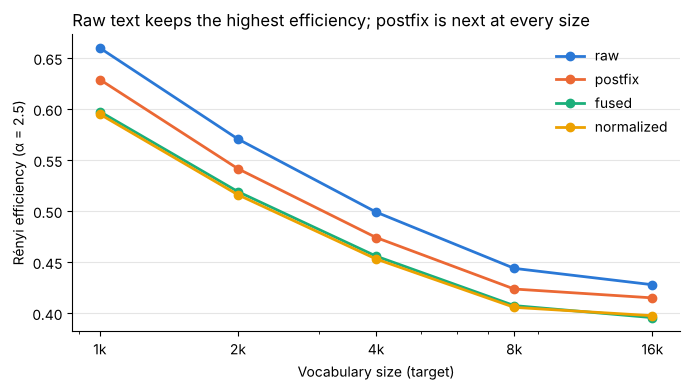

In [9]:
import matplotlib.pyplot as plt

COLORS = {"raw": "#2a78d6", "postfix": "#eb6834", "fused": "#1baf7a", "normalized": "#eda100"}
fig, ax = plt.subplots(figsize=(7, 4))
for name in order:
    d = df[df.layout == name]
    ax.plot(d.vocab_target, d.efficiency, marker="o", markersize=6, linewidth=2,
            color=COLORS[name], label=name)
ax.set_xscale("log")
ax.set_xticks(VOCAB_SIZES, [f"{v // 1000}k" for v in VOCAB_SIZES])
ax.set_xlabel("Vocabulary size (target)")
ax.set_ylabel("Rényi efficiency (α = 2.5)")
ax.set_title("Raw text keeps the highest efficiency; postfix is next at every size", loc="left")
ax.grid(axis="y", color="#e5e5e5")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Conclusions
1. **The ranking is stable.** Efficiency: raw > postfix > fused ≈ normalized at every vocabulary size, so the result isn't an artefact of one setting.
2. **About half of the baseline entropy drop is the stray space token** (≈47% at 8k, ≈52% at 1k; Step 8).
3. **Postfix removes it for real.** Its Rényi entropy matches the "stray space removed" what-if at every size, so two independent methods agree.
4. **Postfix is the shortest normalized layout:** about +7.5% tokens over raw at 8k, against +15.9% (normalized) and +17.0% (fused).
